# 09 — Integrating soil-moisture gap-filling with forest ecohydrology

**Two linked questions; one coherent study:**

1. **SMAP satellite-product feasibility/reconstruction:** How sparse are strictly quality-accepted surface soil-moisture observations, and can a transparent ML model reconstruct *held-out observed SMAP retrievals* better than simple baselines?
2. **Forest ecohydrology context (2017–2022):** How do gridded rainfall seasonality, forest EVI and modeled forest ET vary in the three districts, and how much do missing optical data and ET algorithm-support limits constrain interpretation?

This notebook builds portfolio/paper-draft tables and captions from actual previous outputs. It **does not retrain anything**, fabricate ML metrics, substitute a QA-masked satellite target for in-situ truth, or merge incompatible original and corrected validation scores as though directly comparable.


## 1. Load independently generated results and verify the units/denominators

Required: `04_available_years_monthly_panel.csv`, `05_district_descriptive_summary.csv`, `06_district_evidence_summary.csv`, `06_threshold_sensitivity.csv`, `06_monthly_joint_support.csv`. Notebook 08 results are strictly **optional**, with input fingerprint checks before they are mentioned.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent)
             if (p / 'configs' / 'study_config.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter in the project root or notebooks/.')
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'

def input_csv(name):
    path = TABLES / name
    if not path.exists():
        raise FileNotFoundError(f'Required upstream result missing: {path}')
    return pd.read_csv(path)

panel = input_csv('04_available_years_monthly_panel.csv')
rain = input_csv('05_district_descriptive_summary.csv')
district = input_csv('06_district_evidence_summary.csv')
sensitivity = input_csv('06_threshold_sensitivity.csv')
monthly = input_csv('06_monthly_joint_support.csv')
assert len(panel) == 216 and len(rain) == len(district) == 3
assert set(panel.district) == {'Bandarban', 'Khagrachhari', 'Rangamati'}
assert panel.month.nunique() == 72
assert not panel.duplicated(['district', 'month']).any()
assert len(monthly) == 12 and monthly.district_year_records.eq(18).all()
assert len(sensitivity) == 9 and int(sensitivity.is_baseline.sum()) == 1
baseline = sensitivity[sensitivity.is_baseline].iloc[0]
assert np.isclose(float(baseline.evi_support_min), 0.25)
assert np.isclose(float(baseline.et_main_support_min), 0.50)
assert int(baseline.all_n) == 216 and int(baseline.june_sept_n) == 72
assert int(district.june_sept_jointly_supported_n.sum()) == int(baseline.june_sept_both_supported_n)

rain = rain.sort_values('district').reset_index(drop=True)
district = district.sort_values('district').reset_index(drop=True)
print('Reproduced district rainfall and quality-support result tables:')
display(district.round(2))


Reproduced district rainfall and quality-support result tables:


,district,n_months,evi_supported_n,et_supported_n,jointly_supported_n,june_sept_n,june_sept_jointly_supported_n,june_sept_jointly_supported_pct,annual_rain_mean_mm,mean_june_sept_rain_share_pct
0,Bandarban,72,49,54,44,24,5,20.83,3408.80,78.66
1,Khagrachhari,72,49,55,43,24,4,16.67,2858.65,71.39
2,Rangamati,72,55,56,48,24,6,25.00,3193.28,74.34


## 2. Explicit ML evidence gate

An `08_model_run_manifest.json` declaring *completed* is necessary but **not sufficient**: the original Notebook 07 processed input must still exist and have the same SHA256, and the actual test table must be present. A blocked/incomplete ML experiment remains labelled **pending**. Historical numbers in the original GitHub project are not independent quality-controlled comparisons.


In [2]:
MODEL_MANIFEST = TABLES / '08_model_run_manifest.json'
ML_TABLE = TABLES / '08_temporal_test_metrics.csv'
PROCESSED = ROOT / 'data' / 'processed' / '07_smap_ml_table.csv'
ml_status = 'pending: no verified Notebook 08 held-out SMAP test'
ml_table = None
ml_manifest = {}
if MODEL_MANIFEST.exists():
    ml_manifest = json.loads(MODEL_MANIFEST.read_text(encoding='utf-8'))
    if (ml_manifest.get('status') == 'completed_satellite_product_reconstruction_not_ground_validated'
            and ML_TABLE.exists() and PROCESSED.exists()):
        digest = hashlib.sha256(PROCESSED.read_bytes()).hexdigest()
        if digest == ml_manifest.get('source_sha256'):
            candidate = pd.read_csv(ML_TABLE)
            if {'experiment','RMSE','MAE','bias','R2','n_rows','n_dates','n_grids'}.issubset(candidate.columns):
                assert candidate.RMSE.ge(0).all() and len(candidate) == 3
                ml_table = candidate
                ml_status = 'completed: QA-accepted held-out SMAP reconstruction; NO ground validation'
            else:
                ml_status = 'pending: malformed Notebook 08 test table'
        else:
            ml_status = 'pending: Notebook 07 input changed since Notebook 08 was run'
    else:
        ml_status = 'pending: Notebook 08 model or test data missing/blocked'
print('ML evidence status:', ml_status)
if ml_table is not None:
    display(ml_table.round(5))


ML evidence status: completed: QA-accepted held-out SMAP reconstruction; NO ground validation


,experiment,RMSE,MAE,bias,R2,n_rows,n_dates,n_grids
0,XGBoost/plus_radar_and_vegetation,0.05548,0.04437,-0.00521,0.54352,4042,143,39
1,baseline/global_mean,0.08212,0.06670,0.00065,-0.00006,4042,143,39
2,baseline/calendar_month,0.07006,0.05547,-0.00128,0.27214,4042,143,39


## 3. Final figures — use support denominators, never false certainty

The first figure combines rain magnitude with the percentage of **June–September** district-months (24 per district) passing BOTH exploratory support screens. Its side-by-side panels do **not** imply causation. The second figure shows baseline versus alternative quality screens over the **same 72 wet-season records**. If Notebook 08 is verified, its test scatter and validation candidate chart remain separate in `outputs/figures/08_*`, and may be linked in a portfolio rather than overplotted against hydrological units.


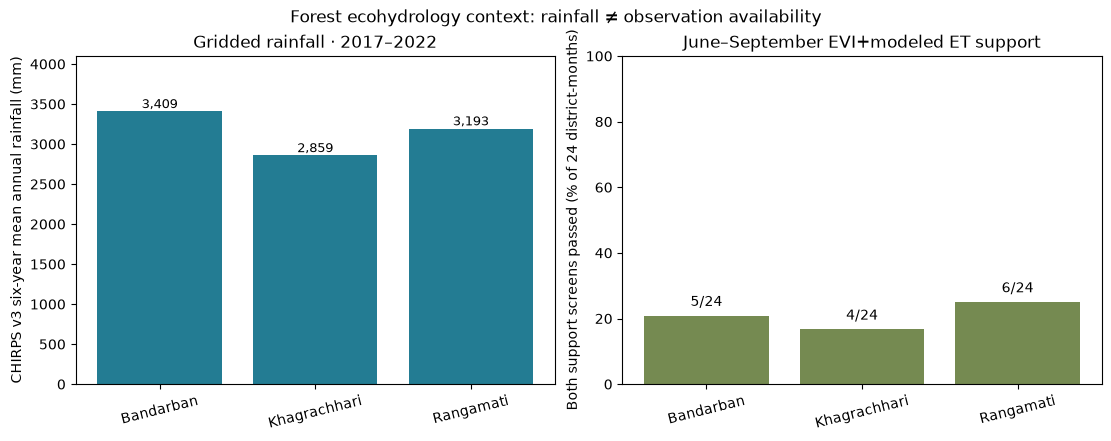

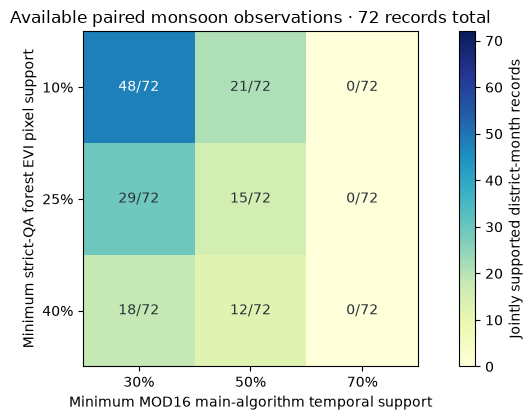

In [3]:
FIGURES.mkdir(parents=True, exist_ok=True)
ordered = list(district.district)
positions = np.arange(len(ordered))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), layout='constrained')
ax[0].bar(positions, district.annual_rain_mean_mm, color='#237c93')
ax[0].set_xticks(positions, ordered, rotation=14)
ax[0].set_ylabel('CHIRPS v3 six-year mean annual rainfall (mm)')
ax[0].set_title('Gridded rainfall · 2017–2022')
for idx, value in enumerate(district.annual_rain_mean_mm):
    ax[0].text(idx, value + 40, f'{value:,.0f}', ha='center', fontsize=9)
ax[0].set_ylim(0, 4100)

bars = ax[1].bar(positions, district.june_sept_jointly_supported_pct, color='#758a51')
ax[1].set_xticks(positions, ordered, rotation=14)
ax[1].set_ylabel('Both support screens passed (% of 24 district-months)')
ax[1].set_ylim(0, 100)
ax[1].set_title('June–September EVI+modeled ET support')
for bar, count in zip(bars, district.june_sept_jointly_supported_n):
    ax[1].text(bar.get_x()+bar.get_width()/2, bar.get_height()+3,
               f'{int(count)}/24', ha='center', fontsize=10)
fig.suptitle('Forest ecohydrology context: rainfall ≠ observation availability', fontsize=12)
fig.savefig(FIGURES / '09_rainfall_and_monsoon_observation_support.png', dpi=210)
plt.show()

fig, ax = plt.subplots(figsize=(8.4, 4.3))
wide = sensitivity.pivot(index='evi_support_min', columns='et_main_support_min',
                         values='june_sept_both_supported_n').sort_index()
im = ax.imshow(wide.to_numpy(dtype=float), cmap='YlGnBu', vmin=0, vmax=72)
ax.set_xticks(range(len(wide.columns)), [f'{v:.0%}' for v in wide.columns])
ax.set_yticks(range(len(wide.index)), [f'{v:.0%}' for v in wide.index])
ax.set_xlabel('Minimum MOD16 main-algorithm temporal support')
ax.set_ylabel('Minimum strict-QA forest EVI pixel support')
ax.set_title('Available paired monsoon observations · 72 records total')
for i in range(len(wide.index)):
    for j in range(len(wide.columns)):
        value = int(wide.iloc[i, j])
        ax.text(j,i,f'{value}/72',ha='center',va='center',
                color='white' if value > 35 else '#263238', fontsize=10)
fig.colorbar(im, ax=ax, label='Jointly supported district-month records')
fig.tight_layout()
fig.savefig(FIGURES / '09_wet_season_qa_sensitivity.png', dpi=210)
plt.show()


## 4. Evidence classification table, limitations and next researchers' questions

All findings are separated into (a) actual satellite/model summaries, (b) reconstructed SMAP-product ML *if* independently tested, (c) unverified historical GitHub claims, and (d) questions requiring ground validation. Forest EVI is **vegetation index**, modeled MOD16 ET is **not eddy-covariance flux**, CHIRPS is **gridded precipitation**, and SMAP is **remotely retrieved surface soil moisture**. The reported percentage of valid *sampled SMAP locations* is **not a polygon-wide area fraction**.


In [4]:
evidence = pd.DataFrame([
    {'topic':'2017–2022 rainfall', 'evidence_status':'descriptive_remote_sensing',
     'ground_validated':False, 'interpretable_as':'Gridded annual and monsoon precipitation patterns'},
    {'topic':'Forest EVI', 'evidence_status':'QA_screened_satellite_observation',
     'ground_validated':False, 'interpretable_as':'Optical greenness where strict-QA pixels remain'},
    {'topic':'Forest modeled ET', 'evidence_status':'modeled_product_support_checked',
     'ground_validated':False, 'interpretable_as':'MOD16A2GF model-product values and main-algorithm support'},
    {'topic':'SMAP QA & product gap pattern', 'evidence_status':'satellite_qa_feasibility',
     'ground_validated':False, 'interpretable_as':'Supported retrieval occurrence on sampled grid postings'},
    {'topic':'SMAP reconstruction ML',
     'evidence_status':'heldout_smap_product_test' if ml_table is not None else 'pending_real_temporal_test',
     'ground_validated':False,
     'interpretable_as':'Held-out accepted SMAP product accuracy' if ml_table is not None
                      else 'No demonstrated ML skill yet'},
    {'topic':'Original GitHub 2021 model', 'evidence_status':'historical_unverified_not_comparable',
     'ground_validated':False,
     'interpretable_as':'Historical proof of concept; target, AOI and test procedures require correction'},
    {'topic':'True forest soil moisture, ET or ecosystem mechanisms',
     'evidence_status':'requires_field_validation_and_process_data',
     'ground_validated':False, 'interpretable_as':'No field inference available'}
])
TABLES.mkdir(parents=True, exist_ok=True)
evidence.to_csv(TABLES / '09_research_evidence_register.csv', index=False)
display(evidence)


,topic,evidence_status,ground_validated,interpretable_as
0,2017–2022 rainfall,descriptive_remote_sensing,False,Gridded annual and monsoon precipitation patterns
1,Forest EVI,QA_screened_satellite_observation,False,Optical greenness where strict-QA pixels remain
2,Forest modeled ET,modeled_product_support_checked,False,MOD16A2GF model-product values and main-algori...
3,SMAP QA & product gap pattern,satellite_qa_feasibility,False,Supported retrieval occurrence on sampled grid...
4,SMAP reconstruction ML,heldout_smap_product_test,False,Held-out accepted SMAP product accuracy
5,Original GitHub 2021 model,historical_unverified_not_comparable,False,"Historical proof of concept; target, AOI and t..."
6,"True forest soil moisture, ET or ecosystem mec...",requires_field_validation_and_process_data,False,No field inference available


## 5. Generate a portable research summary

This Markdown file is a **draft** for your existing research portfolio style. It explicitly reports ML as pending when no verified Notebook 08 run exists. Preserve the source citations, figure captions and limitations when moving to the website or GitHub. Existing `docs/research_showcase.md` and `docs/research_limitations_and_future_directions.md` remain intact until you review any integration changes.


In [5]:
REPORTS.mkdir(parents=True, exist_ok=True)
rain_lines = []
for record in district.itertuples():
    rain_lines.append(f'| {record.district} | {record.annual_rain_mean_mm:,.0f} | '
                      f'{record.mean_june_sept_rain_share_pct:.1f}% | '
                      f'{record.june_sept_jointly_supported_n}/24 |')
wet = int(baseline.june_sept_both_supported_n)
wet_min = int(sensitivity.june_sept_both_supported_n.min())
wet_max = int(sensitivity.june_sept_both_supported_n.max())
if ml_table is None:
    ml_section = ('**Status: pending.** No evaluated Notebook 08 test table is available. '
                  'The original GitHub result remains historical and is not scientifically '
                  'comparable to the corrected QA-target study.')
else:
    rows = [f'| {r.experiment} | {r.RMSE:.5f} | {r.MAE:.5f} | {r.R2:.3f} |'
            for r in ml_table.itertuples()]
    ml_section = ('**Status: evaluated against held-out QA-accepted SMAP retrievals, not field data.**\n\n'
                  '| Experiment | RMSE (m³/m³) | MAE (m³/m³) | R² |\n'
                  '|---|---:|---:|---:|\n' + '\n'.join(rows) +
                  '\n\nDo not interpret these scores as absolute soil-moisture accuracy. '
                  'Temporal correlation, supported-grid selection and satellite errors remain.')

report = f"""# Chittagong Hill Tracts: SMAP gap-filling and forest ecohydrology

*Research portfolio draft, generated {datetime.now(timezone.utc).date().isoformat()} UTC; 2017–2022 context; no ground validation.*

## Question and design

Can strictly QA-accepted enhanced SMAP AM soil-moisture retrievals be reconstructed from climate,
radar, vegetation and terrain predictors, and how do rainfall seasonality and forest vegetation/
ET product-support gaps constrain ecohydrological interpretation in Bandarban, Khagrachhari and Rangamati?

## Observed forest ecohydrology context

| District | Mean annual CHIRPS v3 rainfall (mm; 2017–2022) | June–Sept share | Joint high-support EVI+ET months, Jun–Sep |
|---|---:|---:|---:|
{chr(10).join(rain_lines)}

Across **216 district-months**, **{int(baseline.all_n) - int(baseline.all_both_supported_n)}** lacked
joint support under the declared exploratory 25% strict-QA forest EVI and 50% main-algorithm
modeled-ET support screens. In June–September only **{wet}/72** passed both screens.
Nine alternative support-screen pairs admitted **{wet_min}/72 to {wet_max}/72** June–September
observations: screening sensitivity is a substantive result, not a causal or field-error estimate.

![Rainfall and paired observation support](../figures/09_rainfall_and_monsoon_observation_support.png)

*Figure 1. Mean six-year gridded rainfall alongside percent of June–September district-months passing
both exploratory EVI/ET support screens. Distinct quantities; no causal inference.*

![Monsoon threshold sensitivity](../figures/09_wet_season_qa_sensitivity.png)

*Figure 2. Count of jointly supported June–September district-months at nine alternative thresholds,
from the same denominator of 72.*

## Corrected soil-moisture ML experiment

{ml_section}

## What this study can and cannot establish

**Supported:** gridded rainfall seasonality; available strict-QA optical forest EVI;
modeled MOD16A2GF forest ET with algorithm-support constraints; SMAP observation feasibility;
and, if independently completed, ability to reconstruct some held-out **SMAP product observations**.

**Not supported:** in-situ volumetric soil moisture, local absolute ET accuracy, forest water
balance, causal rainfall–forest moisture response, extrapolation to SMAP cells without QA
observations, or the claim that enhanced SMAP's grid posting equals footprint resolution.

## Future research

1. Quantify QA retrieval availability by land-cover, slope, season and location; pre-register
   inclusion rules and compare with Sentinel-1/optical observation support.
2. Replace center-pixel predictors with scientifically justified SMAP-footprint support and
   test spatially blocked models where the observed sample permits.
3. Collect stratified in-situ 0–5 cm soil-moisture and soil-texture/canopy/topography records;
   coordinate satellite overpass times to independently assess satellite and model bias.
4. Add rain-gauge checks, measured flux/ET references and explicit monsoon cloud sensitivity
   to support stronger ecohydrological claims.
5. Test multiyear and out-of-domain generalization, uncertainties, forest disturbance and
   lagged precipitation mechanisms **only after the QA and validation foundations are sound**.

## Sources and reproducibility

- SMAP enhanced `/005`: https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL3SMP_E_005
- Sentinel-1 GRD dB units: https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD
- CHIRPS v3: https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHC_CHIRPS_V3_DAILY_RNL
- MOD13Q1 EVI: https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1
- MOD16A2GF ET: https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD16A2GF
- Notebooks 04–06 generate context; 07 makes QA-checked SMAP table; 08 independently evaluates
  SMAP-product reconstruction if sufficient observations exist; this Notebook 09 integrates evidence.
"""
destination = REPORTS / '09_integrated_research_summary.md'
destination.write_text(report, encoding='utf-8')
(TABLES / '09_reporting_manifest.json').write_text(json.dumps({
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'ml_status':ml_status,
    'ecohydrology_input_sha256':{
        name:hashlib.sha256((TABLES / name).read_bytes()).hexdigest() for name in [
            '04_available_years_monthly_panel.csv', '05_district_descriptive_summary.csv',
            '06_district_evidence_summary.csv', '06_threshold_sensitivity.csv',
            '06_monthly_joint_support.csv']},
    'is_ground_validated':False,
    'no_automatic_github_push':True
}, indent=2), encoding='utf-8')
print('Saved integrated research draft:', destination)
print('Figures:', FIGURES / '09_rainfall_and_monsoon_observation_support.png',
      FIGURES / '09_wet_season_qa_sensitivity.png')


Saved integrated research draft: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\reports\09_integrated_research_summary.md
Figures: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\figures\09_rainfall_and_monsoon_observation_support.png D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\figures\09_wet_season_qa_sensitivity.png
